# ISIMIP3BASD — daily precipitation, ACCESS-CM2, Southeast Asia

Bias adjustment (BA) and statistical downscaling (SD) with ISIMIP3BASD (Lange 2019) for one variable (pr), one GCM (ACCESS-CM2) and one observational dataset (MSWEP), with an out-of-sample test: the method is trained on **1981–1998** and evaluated against OBS on **1999–2014**, which it never saw.

**Inputs — the only two files needed**

| | file | content |
|---|---|---|
| OBS | `SEA-mswep-pr-1981-end2014.nc` | MSWEP daily precipitation, 0.25°, 140×140 box over Southeast Asia, 1981–2014 |
| GCM | `pr_combined_histssp245_ACCESS-CM2.nc` | ACCESS-CM2 daily precipitation on its native grid (1.25°×1.875°), historical + SSP2-4.5, covering the OBS box with a margin; only 1981–2014 is read |

Units (kg m⁻² s⁻¹ or mm/day) and calendars are harmonised when the files are read (mm/day, `noleap`). Set the two folders in section 1; nothing else needs editing and nothing is written to disk.

**Method**

| step | what it does | functions (section 2) |
|---|---|---|
| coarse grid | OBS 0.25° block-averaged 4×4 → 1°; GCM bilinearly interpolated to the 1° cell centres | `analyze_input_grids` |
| BA, per 1° cell and calendar month | parametric, trend-preserving quantile mapping (Lange 2019) | `ba_one_cell` → `adjust_bias_one_month` → `map_quantiles_parametric_trend_preserving` |
| SD, per 1° cell and calendar month, 1° → 0.25° | bilinear remap, then weighted-sum-preserving MBCn against the fine OBS (Lange 2019, after Cannon 2018) | `sd_one_cell` → `remapbil`, `downscale_one_month` → `weighted_sum_preserving_mbcn` |

**Settings (pr)**

| parameter | value | meaning |
|---|---|---|
| `CAL`, `VAL` | 1981–1998, 1999–2014 | training period, evaluation period |
| `N_COARSEN` | 4 | 0.25° → 1° working grid |
| `C['dist']`, `C['tp']` | gamma, mixed | distribution and trend preservation of BA (Lange 2019, Table 2) |
| `C['lb']`, `C['lt']` | 0, 0.1 mm/day | lower bound and threshold: values ≤ 0.1 mm/day are dry days |
| `C['apv']` | True | adjust p-values |
| `N_Q` | 50 | quantiles (BA and SD) |
| `N_ITER_SD` | 20 | MBCn iterations |
| `MCF`, `MAF`, `P_EPS` | 100, 9, 1e-10 | limits of change factor, adjustment factor and p-values |
| `SEED` | 0 | random seed; the run is reproducible |
| `N_PROC` | CPUs − 1 | processes for the loop over 1° cells (speed only) |

**Requirements**: numpy, scipy, pandas, xarray, matplotlib, cartopy, shapely; joblib for parallel cells (optional). Runtime ≈ 15 min with 15 processes. Cells build on each other: run them top to bottom once, after that any cell can be re-run on its own.

*The functions in section 2 are ISIMIP3BASD v3.0.2 (© 2022 Potsdam Institute for Climate Impact Research, GNU AGPL v3 or later); this notebook is distributed under the same license.*

## 1 · Setup
Inputs, settings and helpers.

In [1]:
import os, time, gc, warnings, numpy as np, pandas as pd, xarray as xr, matplotlib.pyplot as plt
import scipy.stats as sps, scipy.linalg as spl, scipy.interpolate as spi
import cartopy.crs as ccrs, cartopy.feature as cfeature, cartopy.io.shapereader as shpreader, shapely
from pandas import Series
try: from joblib import Parallel, delayed
except ImportError: Parallel = None                                                            # without joblib the cells run one after another (same result)
warnings.filterwarnings('ignore'); plt.rcParams['text.usetex'] = False
# ======================================== CONFIG (your data dirs) ========================================
OBS_DIR, IN_ROOT = r"D:/G_data/obs-SEA", r"D:/G_data/CMIP6-histssp-input"
V, MOD, OBS_NAME, SCN = 'pr', 'ACCESS-CM2', 'MSWEP', 'ssp245'
OBS_FILE = rf"{OBS_DIR}/SEA-mswep-pr-1981-end2014.nc"
GCM_FILE = rf"{IN_ROOT}/histssp{SCN[3:]}/{V}_combined_histssp{SCN[3:]}_{MOD}.nc"               # only its 1981-2014 (historical) part is used
CAL, VAL = ('1981', '1998'), ('1999', '2014')                                                  # calibration -> validation (out of sample)
N_COARSEN, N_Q, N_ITER_SD, SEED = 4, 50, 20, 0                                                 # 0.25° -> 1° | quantiles | MBCn iterations | random seed
MCF, MAF, P_EPS = 100., 9., 1e-10                                                              # max change factor, max adjustment factor, p-value cap
MONTHS = list(range(1, 13)); N_PROC = max(1, (os.cpu_count() or 2) - 1); CHUNK = 100          # N_PROC / CHUNK: speed only, the result does not depend on them
# pr settings (Lange 2019, Table 2); sd_* are the bounds used in SD
C = dict(units='mm/day', dist='gamma', tp='mixed', lb=0., lt=.1, ub=None, ut=None, detrend=False, apv=True, uccs=False, tbf=False, iaiu=np.nan,
         sd_lb=0., sd_lt=.1, sd_ub=None, sd_ut=None, thr=1.)
TAGCFG = f'cal={CAL[0]}-{CAL[1]} val={VAL[0]}-{VAL[1]} df={N_COARSEN} nq={N_Q} n_iter={N_ITER_SD} dist={C["dist"]} tp={C["tp"]} lt={C["lt"]} seed={SEED}'
for _p in (OBS_FILE, GCM_FILE): assert os.path.exists(_p), f'not found: {_p}'
print(f'N_PROC={N_PROC} ({"parallel, joblib" if Parallel is not None and N_PROC > 1 else "serial"}) | {TAGCFG}', flush=True)
# ======================================== HELPERS ========================================
def std(ds):
    ren = {a:b for a,b in [('latitude','lat'),('longitude','lon'),('Latitude','lat'),('Longitude','lon')] if a in ds.dims or a in ds.coords}
    ds = ds.rename(ren) if ren else ds
    if ds.lat.size > 1 and float(ds.lat[0]) > float(ds.lat[-1]): ds = ds.sortby('lat')
    if float(ds.lon.min()) < 0: ds = ds.assign_coords(lon=(ds.lon % 360)).sortby('lon')
    return ds
NL = lambda d: d if d.time.dt.calendar=='noleap' else d.convert_calendar('noleap', align_on='year' if d.time.dt.calendar=='360_day' else 'date')
Tz = lambda d: d.transpose('time','lat','lon')
def fix_units(da, v, name):
    u = str(da.attrs.get('units','')).lower().replace(' ',''); s = da.isel(time=slice(0, 366)); msg = None
    if v == 'pr' and (u in ('kgm-2s-1','kg/m2/s','kgm**-2s**-1') or 0 < float(s.max()) < 0.01): da, msg = da*86400., 'x86400'
    if msg: print(f'    !! {name}: units="{u}" -> {msg}', flush=True)
    da.attrs = {'units': C['units']}; return da
def land_mask(lat, lon):
    """Natural Earth 10m land polygons (cartopy) evaluated at the grid points; None if the polygons cannot be loaded."""
    try:
        lo = (np.asarray(lon) + 180) % 360 - 180; box = shapely.box(lo.min()-1, lat.min()-1, lo.max()+1, lat.max()+1)
        g = shapely.union_all([shapely.intersection(x, box) for x in shpreader.Reader(shpreader.natural_earth('10m', 'physical', 'land')).geometries() if x.intersects(box)])
        LO, LA = np.meshgrid(lo, lat); return shapely.contains_xy(g, LO, LA)
    except Exception as e: print(f'!! Natural Earth land unavailable ({type(e).__name__}: {e}) -> mask = finite OBS only', flush=True); return None

C:\Users\HOASEN\AppData\Roaming\Python\Python39\site-packages\pandas\core\arrays\masked.py:61: UserWarning: Pandas requires version '1.3.6' or newer of 'bottleneck' (version '1.3.5' currently installed).
  from pandas.core import (


N_PROC=15 (parallel, joblib) | cal=1981-1998 val=1999-2014 df=4 nq=50 n_iter=20 dist=gamma tp=mixed lt=0.1 seed=0


## 2 · ISIMIP3BASD
The functions of ISIMIP3BASD v3.0.2 needed for one variable in calendar-month mode, unchanged in what they compute. `ba_one_cell` and `sd_one_cell` apply them to one coarse cell held in memory; `ba_coarse` and `downscale_all` loop over the cells. Every random draw is seeded inside the cell, so the result does not depend on the order or the number of processes.

In [2]:
# ======================================== ISIMIP3BASD v3.0.2 (Lange 2019): helper functions ========================================
def assert_consistency_of_bounds_and_thresholds(lower_bound=None, lower_threshold=None, upper_bound=None, upper_threshold=None):
    lower, upper = lower_bound is not None and lower_threshold is not None, upper_bound is not None and upper_threshold is not None
    if not lower: assert lower_bound is None and lower_threshold is None, 'give lower_bound and lower_threshold together'
    if not upper: assert upper_bound is None and upper_threshold is None, 'give upper_bound and upper_threshold together'
    if lower: assert lower_bound < lower_threshold, 'lower_bound >= lower_threshold'
    if upper: assert upper_bound > upper_threshold, 'upper_bound <= upper_threshold'
    if lower and upper: assert lower_threshold < upper_threshold, 'lower_threshold >= upper_threshold'
def assert_consistency_of_distribution_and_bounds(distribution, lower_bound=None, lower_threshold=None, upper_bound=None, upper_threshold=None):
    if distribution is None: return
    lower, upper = lower_bound is not None and lower_threshold is not None, upper_bound is not None and upper_threshold is not None; msg = distribution + ' distribution '
    if distribution == 'normal': assert not lower and not upper, msg + 'can not have bounds'
    elif distribution in ('weibull', 'gamma', 'rice'): assert lower and not upper, msg + 'must only have lower bound'
    elif distribution == 'beta': assert lower and upper, msg + 'must have lower and upper bound'
    else: raise AssertionError(msg + 'not supported')
def assert_no_infs_or_nans(x_before, x_after):
    if np.any(np.logical_or(np.isinf(x_after), np.isnan(x_after))): raise ValueError('found infs or nans in x_after')
def grid_cell_weights(lat, lon):
    """Grid cell area weights cos(lat) of a regular lat-lon grid, shape (lat, lon)."""
    w = np.empty((lat.size, lon.size), dtype=np.float32); w[:] = np.cos(np.deg2rad(lat)).reshape(-1, 1); return w
def analyze_input_grids(coords_coarse, coords_fine):
    """Checks that every coarse cell holds an integer number of uniformly spaced fine cells; returns downscaling factors, ascending, circular."""
    downscaling_factors, ascending, circular = [], [], []
    for i, x in enumerate(coords_coarse):
        y = coords_fine[i]; assert len(x) > 1, f'grid size issue in spatial dimension {i}'
        msg = f'downscaling factor issue in spatial dimension {i}'; assert len(y) % len(x) == 0, msg; f = len(y) // len(x); assert f > 1, msg
        downscaling_factors.append(f); dx, dy = np.diff(x), np.diff(y)
        assert np.all(dx > 0) and np.all(dy > 0) or np.all(dx < 0) and np.all(dy < 0), f'monotonicity issue in spatial dimension {i}'
        a = dx[0] > 0; ascending.append(a); circular.append(np.allclose(x[:1] - dx[:1] + (360 if a else -360), x[-1]))
        d = np.delete(dy, np.arange(f-1, dy.size, f)).reshape(f-1, len(x))
        for j in range(f-2): assert np.allclose(d[:,j], d[:,j+1]), f'uniform spacing issue in spatial dimension {i}'
        s = .5 * (np.concatenate((dx[:1], dx)) + np.concatenate((dx, dx[-1:]))); t = np.arange(1, f + 1) / f
        y_expected = np.repeat(x - .5 * s, f) + np.repeat(s, f) * np.tile(t - .5 * t[0], x.size)
        assert np.allclose(y, y_expected), f'expected coordinate issue in spatial dimension {i}'
    return np.array(downscaling_factors), tuple(ascending), tuple(circular)
def xipm1(x, i):
    """Points of x at i-1, i, i+1, extrapolated linearly beyond the ends of x."""
    n = x.size; assert n > 1, 'x too short'
    return np.array([2 * x[0] - x[1] if i == 0 else x[i-1], x[i], 2 * x[-1] - x[-2] if i == n - 1 else x[i+1]])
def remapbil(ivalues, igrid, ogrid, ascending):
    """Bilinear (multilinear) remapping from the 3x3 coarse window igrid to the fine points ogrid; nans are filled with the central coarse value."""
    indices, norm_distances = [], []
    i_ascending = lambda x, y: np.searchsorted(y, x) - 1
    i_descending = lambda x, y: y.size - 1 - np.searchsorted(y, x, 'right', np.arange(y.size - 1, -1, -1))
    for a, x, y in zip(ascending, ogrid, igrid):
        i = i_ascending(x, y) if a else i_descending(x, y); indices.append(i); norm_distances.append((x - y[i]) / (y[i + 1] - y[i]))
    ndim = len(igrid); wshape_trailing = (2,) * ndim + (1,) * (ivalues.ndim - ndim); gshape = tuple(len(g) for g in ogrid)
    ovalues = np.empty(gshape + ivalues.shape[ndim:], dtype=ivalues.dtype)
    for oind in np.ndindex(gshape):
        weights = np.ones((2,)*ndim, dtype=ivalues.dtype); edges = tuple(np.array([index[oind[i]], index[oind[i]]+1]) for i, index in enumerate(indices))
        for i, edge in enumerate(edges):
            w = norm_distances[i][oind[i]]; weights *= np.where(edge == indices[i][oind[i]], 1 - w, w).reshape((1,) * i + (2,) + (1,) * (ndim - 1 - i))
        result = np.sum(ivalues[np.ix_(*edges)] * weights.reshape(wshape_trailing), axis=tuple(np.arange(ndim)))
        i_nan = np.isnan(result); result[i_nan] = ivalues[(1,) * ndim][i_nan]; ovalues[oind] = result
    return ovalues
def subtract_or_add_trend(x, years, trend=None):
    """Removes a significant (p < .05) linear trend of the annual means, or adds a given trend back."""
    assert x.size == years.size, 'size of x != size of years'; unique_years = np.unique(years)
    if trend is None:
        r = sps.linregress(unique_years, np.array([np.mean(x[years == y]) for y in unique_years]))
        trend = r.slope * (unique_years - np.mean(unique_years)) if r.pvalue < .05 else np.zeros(unique_years.size, dtype=x.dtype); return_trend = True
    else:
        assert trend.size == unique_years.size, 'size of trend array != number of unique years'; trend = -trend; return_trend = False
    if np.any(trend):
        y = np.empty_like(x)
        for i, year in enumerate(unique_years): y[years == year] = x[years == year] - trend[i]
    else: y = x.copy()
    return (y, trend) if return_trend else y
def percentile1d(a, p):
    """Fast np.percentile with linear interpolation for 1-d arrays; p in [0, 1]."""
    n = a.size - 1; b = np.sort(a); i = n * p; i_below = np.floor(i).astype(int); w_above = i - i_below
    return b[i_below] * (1. - w_above) + b[i_below + (i_below < n)] * w_above
def map_quantiles_non_parametric_trend_preserving(x_obs_hist, x_sim_hist, x_sim_fut, trend_preservation='additive', n_quantiles=50,
                                                  max_change_factor=100., max_adjustment_factor=9., adjust_obs=False, lower_bound=None, upper_bound=None):
    """Augmented quantile delta mapping (after Cannon et al. 2015); with adjust_obs=True it transfers the simulated change to the observations."""
    assert n_quantiles > 0, 'n_quantiles <= 0'; n = min([n_quantiles + 1, x_obs_hist.size, x_sim_hist.size, x_sim_fut.size])
    if n < 2: warnings.warn('not enough input data'); return x_obs_hist if adjust_obs else x_sim_fut
    elif n < n_quantiles + 1: warnings.warn('due to little input data: reducing n_quantiles to %i' % (n-1))
    p_zeroone = np.linspace(0., 1., n)
    q_obs_hist, q_sim_hist, q_sim_fut = percentile1d(x_obs_hist, p_zeroone), percentile1d(x_sim_hist, p_zeroone), percentile1d(x_sim_fut, p_zeroone)
    p = np.interp(x_obs_hist, q_obs_hist, p_zeroone) if adjust_obs else np.interp(x_sim_fut, q_sim_fut, p_zeroone)
    F_sim_fut_inv, F_sim_hist_inv, F_obs_hist_inv = np.interp(p, p_zeroone, q_sim_fut), np.interp(p, p_zeroone, q_sim_hist), np.interp(p, p_zeroone, q_obs_hist)
    if trend_preservation == 'bounded':
        assert lower_bound is not None and upper_bound is not None, 'lower_bound or upper_bound not specified'; assert lower_bound < upper_bound, 'lower_bound >= upper_bound'
        y = ccs_transfer_sim2obs(F_obs_hist_inv, F_sim_hist_inv, F_sim_fut_inv, lower_bound, upper_bound)
    elif trend_preservation in ['mixed', 'multiplicative']:
        assert max_change_factor > 1, 'max_change_factor <= 1'
        with np.errstate(divide='ignore', invalid='ignore'):
            y = np.where(F_sim_hist_inv == 0, 1., F_sim_fut_inv/F_sim_hist_inv); y[y > max_change_factor] = max_change_factor; y[y < 1. / max_change_factor] = 1. / max_change_factor
        y *= F_obs_hist_inv
        if trend_preservation == 'mixed':
            assert max_adjustment_factor > 1, 'max_adjustment_factor <= 1'
            y_additive = F_obs_hist_inv + F_sim_fut_inv - F_sim_hist_inv; fraction_multiplicative = np.zeros_like(y); fraction_multiplicative[F_sim_hist_inv >= F_obs_hist_inv] = 1.
            i_transition = np.logical_and(F_sim_hist_inv < F_obs_hist_inv, F_obs_hist_inv < max_adjustment_factor * F_sim_hist_inv)
            fraction_multiplicative[i_transition] = .5 * (1. + np.cos((F_obs_hist_inv[i_transition] / F_sim_hist_inv[i_transition] - 1.) * np.pi / (max_adjustment_factor - 1.)))
            y = fraction_multiplicative * y + (1. - fraction_multiplicative) * y_additive
    elif trend_preservation == 'additive': y = F_obs_hist_inv + F_sim_fut_inv - F_sim_hist_inv
    else: raise AssertionError('trend_preservation = ' + trend_preservation + ' not supported')
    return y
def map_quantiles_non_parametric_with_constant_extrapolation(x, q_sim, q_obs):
    """Empirical quantile mapping; values beyond the range of q_sim are shifted by the constant offset at the ends."""
    assert q_sim.size == q_obs.size; lunder, lover = x < q_sim[0], x > q_sim[-1]; y = np.interp(x, q_sim, q_obs)
    y[lunder] = x[lunder] + (q_obs[0] - q_sim[0]); y[lover] = x[lover] + (q_obs[-1] - q_sim[-1]); return y
def map_quantiles_non_parametric_brute_force(x, y):
    """Maps x onto the empirical distribution of y."""
    if x.size == 0: warnings.warn('found no values in x: returning x'); return x
    if np.unique(y).size < 2: warnings.warn('found fewer then 2 different values in y: returning x'); return x
    return np.interp((sps.rankdata(x) - 1.) / x.size, np.linspace(0., 1., y.size), np.sort(y))
def ccs_transfer_sim2obs(x_obs_hist, x_sim_hist, x_sim_fut, lower_bound=0., upper_bound=1.):
    """Transfers the simulated change (x_sim_hist -> x_sim_fut) to x_obs_hist, respecting the bounds."""
    if np.isscalar(x_obs_hist): x_obs_hist = np.array([x_obs_hist])
    if np.isscalar(x_sim_hist): x_sim_hist = np.array([x_sim_hist])
    if np.isscalar(x_sim_fut): x_sim_fut = np.array([x_sim_fut])
    assert lower_bound < upper_bound, 'lower_bound >= upper_bound'
    for x_name, x in zip(['x_obs_hist', 'x_sim_hist', 'x_sim_fut'], [x_obs_hist, x_sim_hist, x_sim_fut]):
        assert np.all(x >= lower_bound), 'found ' + x_name + ' < lower_bound'; assert np.all(x <= upper_bound), 'found ' + x_name + ' > upper_bound'
    i_neg_bias, i_zero_bias, i_pos_bias = x_sim_hist < x_obs_hist, x_sim_hist == x_obs_hist, x_sim_hist > x_obs_hist
    i_additive = np.logical_or(np.logical_and(i_neg_bias, x_sim_fut < x_sim_hist), np.logical_and(i_pos_bias, x_sim_fut > x_sim_hist))
    x_obs_fut = np.empty_like(x_obs_hist)
    x_obs_fut[i_neg_bias] = upper_bound - (upper_bound - x_obs_hist[i_neg_bias]) * (upper_bound - x_sim_fut[i_neg_bias]) / (upper_bound - x_sim_hist[i_neg_bias])
    x_obs_fut[i_zero_bias] = x_sim_fut[i_zero_bias]
    x_obs_fut[i_pos_bias] = lower_bound + (x_obs_hist[i_pos_bias] - lower_bound) * (x_sim_fut[i_pos_bias] - lower_bound) / (x_sim_hist[i_pos_bias] - lower_bound)
    x_obs_fut[i_additive] = x_obs_hist[i_additive] + x_sim_fut[i_additive] - x_sim_hist[i_additive]
    x_obs_fut = np.maximum(lower_bound, np.minimum(upper_bound, x_obs_fut)); return x_obs_fut[0] if x_obs_fut.size == 1 else x_obs_fut
def transfer_odds_ratio(p_obs_hist, p_sim_hist, p_sim_fut):
    """Multiplies the historical observed odds by the simulated future/historical odds ratio (after Switanek et al. 2017)."""
    x, y, z = np.sort(p_obs_hist), np.sort(p_sim_hist), np.sort(p_sim_fut)
    if x.size != z.size or y.size != z.size:
        p_z = np.linspace(0, 1, z.size); x = spi.interp1d(np.linspace(0, 1, x.size), x)(p_z); y = spi.interp1d(np.linspace(0, 1, y.size), y)(p_z)
    A = x * (1. - y) * z; B = (1. - x) * y * (1. - z); z_scaled = 1. / (1. + B / A)
    z_min = 1. / (1. + np.power(10., 1. - np.log10(x / (1. - x)))); z_max = 1. / (1. + np.power(10., -1. - np.log10(x / (1. - x))))
    z_scaled = np.maximum(z_min, np.minimum(z_max, z_scaled)); return z_scaled[np.argsort(np.argsort(p_sim_fut))]
def randomize_censored_values_core(y, bound, threshold, inverse, power, lower):
    i = y <= threshold if lower else y >= threshold
    if inverse: y[i] = bound
    else:
        n = np.sum(i)
        if n:
            v = bound + np.power(np.random.uniform(0, 1, n), power) * (threshold - bound); s = Series(y[i])
            r = s.sample(frac=1).rank(method='first').reindex_like(s); y[i] = np.sort(v)[r.values.astype(int) - 1]
def randomize_censored_values(x, lower_bound=None, lower_threshold=None, upper_bound=None, upper_threshold=None, inplace=False, inverse=False,
                              seed=None, lower_power=1., upper_power=1.):
    """Replaces values beyond the thresholds by random values between threshold and bound (ranks kept), or sets them back to the bound (inverse)."""
    y = x if inplace else x.copy()
    if seed is not None: np.random.seed(seed)
    if lower_bound is not None and lower_threshold is not None: randomize_censored_values_core(y, lower_bound, lower_threshold, inverse, lower_power, True)
    if upper_bound is not None and upper_threshold is not None: randomize_censored_values_core(y, upper_bound, upper_threshold, inverse, upper_power, False)
    return y
def check_shape_loc_scale(spsdotwhat, shape_loc_scale):
    if np.any(np.isnan(shape_loc_scale)) or np.any(np.isinf(shape_loc_scale)): return 1
    elif spsdotwhat == sps.norm: return 2 if shape_loc_scale[1] <= 0 else 0
    elif spsdotwhat in [sps.weibull_min, sps.gamma, sps.rice]: return 2 if shape_loc_scale[0] <= 0 or shape_loc_scale[2] <= 0 else 0
    elif spsdotwhat == sps.beta: return 2 if shape_loc_scale[0] <= 0 or shape_loc_scale[1] <= 0 or shape_loc_scale[0] > 1e10 or shape_loc_scale[1] > 1e10 else 0
    else: return 3
def fit(spsdotwhat, x, fwords):
    """Maximum likelihood fit (method of moments as fallback for gamma and beta); None if the fit fails or KS statistic > .5."""
    if np.unique(x).size < 2: warnings.warn('found fewer then 2 different values in x: returning None'); return None
    try: shape_loc_scale = spsdotwhat.fit(x, **fwords)
    except Exception: shape_loc_scale = (np.nan,)
    if check_shape_loc_scale(spsdotwhat, shape_loc_scale):
        msg = 'maximum likelihood estimation'
        if spsdotwhat == sps.gamma:
            msg += ' failed: method of moments'; x_mean = np.mean(x) - fwords['floc']; x_var = np.var(x); scale = x_var / x_mean
            shape_loc_scale = (x_mean / scale, fwords['floc'], scale)
        elif spsdotwhat == sps.beta:
            msg += ' failed: method of moments'; y = (x - fwords['floc']) / fwords['fscale']; y_mean = np.mean(y); y_var = np.var(y)
            p = np.square(y_mean) * (1. - y_mean) / y_var - y_mean; shape_loc_scale = (p, p * (1. - y_mean) / y_mean, fwords['floc'], fwords['fscale'])
    else: msg = ''
    if check_shape_loc_scale(spsdotwhat, shape_loc_scale): warnings.warn(msg + ' failed: returning None'); return None
    elif msg != '': msg += ' succeeded'
    if sps.kstest(x, spsdotwhat.name, args=shape_loc_scale)[0] > .5: warnings.warn('fit is not good: returning None'); return None
    if msg != '': warnings.warn(msg)
    return shape_loc_scale
def only_missing_values_in_at_least_one_dataset(data):
    for key, array_list in data.items():
        only_missing_values = True
        for a in array_list:
            if not isinstance(a, np.ma.MaskedArray): only_missing_values = False; break
            m = a.mask
            if not isinstance(m, np.ndarray):
                if m: continue
                else: only_missing_values = False; break
            if not np.all(m): only_missing_values = False; break
        if only_missing_values: return True
    return False
def only_missing_values_in_at_least_one_time_series(data):
    for key, a in data.items():
        assert a.ndim in [1, 2], f'{key} array has {a.ndim} dimensions'
        if isinstance(a, np.ma.MaskedArray):
            m = a.mask
            if isinstance(m, np.ndarray):
                if (a.ndim == 1 and np.all(m)) or (a.ndim == 2 and np.any(np.all(m, axis=0))): return True
            elif m: return True
    return False
def average_respecting_bounds(x, lower_bound=None, lower_threshold=None, upper_bound=None, upper_threshold=None):
    y = x.copy()
    if lower_bound is not None and lower_threshold is not None: y[y <= lower_threshold] = lower_bound
    if upper_bound is not None and upper_threshold is not None: y[y >= upper_threshold] = upper_bound
    return np.mean(y)
def average_valid_values(a, if_all_invalid_use=np.nan, lower_bound=None, lower_threshold=None, upper_bound=None, upper_threshold=None):
    """Mean of the valid values per location (values beyond thresholds set to the bound first); if_all_invalid_use if there are none."""
    b = np.ma.masked_invalid(a, copy=False); d = b.data; l_invalid = b.mask
    average1d = lambda x, l: if_all_invalid_use if np.all(l) else average_respecting_bounds(x[np.logical_not(l)], lower_bound, lower_threshold, upper_bound, upper_threshold)
    space_shape = a.shape[1:]
    if len(space_shape):
        average = np.empty(space_shape, dtype=np.float32)
        for i in np.ndindex(space_shape): j = (slice(None, None),) + i; average[i] = average1d(d[j], l_invalid[j])
    else: average = average1d(d, l_invalid)
    return average
def sample_invalid_values(a, seed=None, if_all_invalid_use=np.nan, warn=False):
    """Replaces missing/inf/nan values by values sampled from the valid ones of the same location (trend-mimicking order)."""
    space_shape = a.shape[1:]
    if len(space_shape): assert isinstance(if_all_invalid_use, np.ndarray) and if_all_invalid_use.shape == space_shape, 'shapes of a and if_all_invalid_use do not fit'
    else: assert np.isscalar(if_all_invalid_use), 'expected if_all_invalid_use to be scalar'
    if isinstance(a, np.ma.MaskedArray):
        d = a.data; m = a.mask
        if not isinstance(m, np.ndarray): m = np.empty(a.shape, dtype=bool); m[:] = a.mask
    else: d = a; m = np.zeros(a.shape, dtype=bool)
    l_invalid = np.logical_or(np.logical_or(m, np.isinf(d)), np.isnan(d))
    if not np.sum(l_invalid): return d, None
    if len(space_shape):
        d_replaced = np.empty_like(d)
        for i in np.ndindex(space_shape): j = (slice(None, None),) + i; d_replaced[j] = sample_invalid_values_core(d[j], seed, if_all_invalid_use[i], warn, l_invalid[j])
    else: d_replaced = sample_invalid_values_core(d, seed, if_all_invalid_use, warn, l_invalid)
    return d_replaced, l_invalid
def sample_invalid_values_core(d, seed, if_all_invalid_use, warn, l_invalid):
    n_invalid = np.sum(l_invalid)
    if not n_invalid: return d
    n_valid = d.size - n_invalid
    if not n_valid:
        if np.isnan(if_all_invalid_use): raise ValueError('found no valid value(s)')
        d_replaced = np.empty_like(d); d_replaced[:] = if_all_invalid_use; return d_replaced
    l_valid = np.logical_not(l_invalid); d_valid = d[l_valid]
    if seed is not None: np.random.seed(seed)
    d_sampled = percentile1d(d_valid, np.random.random_sample(n_invalid)); d_replaced = d.copy()
    if n_valid == 1: d_replaced[l_invalid] = d_sampled
    else:
        r_valid_interp1d = spi.interp1d(np.where(l_valid)[0], np.argsort(np.argsort(d_valid)), fill_value='extrapolate')
        d_replaced[l_invalid] = np.sort(d_sampled)[np.argsort(np.argsort(r_valid_interp1d(np.where(l_invalid)[0])))]
    return d_replaced
def generateCREmatrix(n):
    """Random orthogonal n x n matrix from the circular real ensemble."""
    q, r = spl.qr(np.random.randn(n, n)); d = np.diagonal(r); return q * (d / np.abs(d))
def generate_rotation_matrix_fixed_first_axis(v, transpose=False):
    """Orthogonal matrix whose first column (row if transpose) is v/|v|."""
    assert np.all(v > 0), 'all elements of v have to be positive'; a = np.diag(np.ones_like(v)); a[:,0] = v; q, r = spl.qr(a); return -q.T if transpose else -q

In [3]:
# ======================================== ISIMIP3BASD v3.0.2: bias adjustment (BA) ========================================
def map_quantiles_parametric_trend_preserving(x_obs_hist, x_sim_hist, x_sim_fut, distribution=None, trend_preservation='additive', adjust_p_values=False,
        lower_bound=None, lower_threshold=None, upper_bound=None, upper_threshold=None, unconditional_ccs_transfer=False, trendless_bound_frequency=False,
        n_quantiles=50, p_value_eps=1e-10, max_change_factor=100., max_adjustment_factor=9.):
    """Trend-preserving parametric quantile mapping (Lange 2019): the simulated change is first transferred to the observations by quantile delta
       mapping, then x_sim_fut is mapped onto the distribution of these pseudo-future observations."""
    lower, upper = lower_bound is not None and lower_threshold is not None, upper_bound is not None and upper_threshold is not None
    i_obs_hist, i_sim_hist, i_sim_fut = np.ones(x_obs_hist.shape, dtype=bool), np.ones(x_sim_hist.shape, dtype=bool), np.ones(x_sim_fut.shape, dtype=bool)
    if lower: i_obs_hist, i_sim_hist, i_sim_fut = i_obs_hist & (x_obs_hist > lower_threshold), i_sim_hist & (x_sim_hist > lower_threshold), i_sim_fut & (x_sim_fut > lower_threshold)
    if upper: i_obs_hist, i_sim_hist, i_sim_fut = i_obs_hist & (x_obs_hist < upper_threshold), i_sim_hist & (x_sim_hist < upper_threshold), i_sim_fut & (x_sim_fut < upper_threshold)
    if unconditional_ccs_transfer:
        x_target = map_quantiles_non_parametric_trend_preserving(x_obs_hist, x_sim_hist, x_sim_fut, trend_preservation, n_quantiles,
                                                                 max_change_factor, max_adjustment_factor, True, lower_bound, upper_bound)
    else:
        x_target = x_obs_hist.copy()
        x_target[i_obs_hist] = map_quantiles_non_parametric_trend_preserving(x_obs_hist[i_obs_hist], x_sim_hist[i_sim_hist], x_sim_fut[i_sim_fut],
                                   trend_preservation, n_quantiles, max_change_factor, max_adjustment_factor, True, lower_threshold, upper_threshold)
    if lower:
        p_lower = lambda x: np.mean(x <= lower_threshold)
        p_lower_target = p_lower(x_obs_hist) if trendless_bound_frequency else ccs_transfer_sim2obs(p_lower(x_obs_hist), p_lower(x_sim_hist), p_lower(x_sim_fut))
    if upper:
        p_upper = lambda x: np.mean(x >= upper_threshold)
        p_upper_target = p_upper(x_obs_hist) if trendless_bound_frequency else ccs_transfer_sim2obs(p_upper(x_obs_hist), p_upper(x_sim_hist), p_upper(x_sim_fut))
    if lower and upper:
        p_lower_or_upper_target = p_lower_target + p_upper_target
        if p_lower_or_upper_target > 1 + 1e-10:
            warnings.warn('sum of p_lower_target and p_upper_target exceeds one'); p_lower_target /= p_lower_or_upper_target; p_upper_target /= p_lower_or_upper_target
    x_source = x_sim_fut; y = x_source.copy(); i_source = np.ones(x_source.shape, dtype=bool); i_target = np.ones(x_target.shape, dtype=bool)
    if lower:
        lower_threshold_source = percentile1d(x_source, np.array([p_lower_target]))[0] if p_lower_target > 0 else lower_bound if not upper else lower_bound - 1e-10 * (upper_bound - lower_bound)
        i_lower = x_source <= lower_threshold_source; i_source = np.logical_and(i_source, np.logical_not(i_lower)); i_target = np.logical_and(i_target, x_target > lower_threshold); y[i_lower] = lower_bound
    if upper:
        upper_threshold_source = percentile1d(x_source, np.array([1.-p_upper_target]))[0] if p_upper_target > 0 else upper_bound if not lower else upper_bound + 1e-10 * (upper_bound - lower_bound)
        i_upper = x_source >= upper_threshold_source; i_source = np.logical_and(i_source, np.logical_not(i_upper)); i_target = np.logical_and(i_target, x_target < upper_threshold); y[i_upper] = upper_bound
    while np.any(i_source):
        if not np.any(i_target): warnings.warn('unable to do any quantile mapping: leaving %i value(s) unadjusted' % np.sum(i_source)); break
        x_source_fit, x_target_fit = x_source[i_sim_fut], x_target[i_target]
        spsdotwhat = {'normal': sps.norm, 'weibull': sps.weibull_min, 'gamma': sps.gamma, 'beta': sps.beta, 'rice': sps.rice}.get(distribution)
        if spsdotwhat is None: x_source_map = x_source[i_source]; shape_loc_scale_source = shape_loc_scale_target = None
        else:
            x_source_map = map_quantiles_non_parametric_brute_force(x_source[i_source], x_source_fit) if lower or upper else x_source
            floc = lower_threshold if lower else None; fscale = upper_threshold - lower_threshold if lower and upper else None
            fwords = {'floc': floc} if distribution in ['rice', 'weibull'] else {'floc': floc, 'fscale': fscale}
            shape_loc_scale_source = fit(spsdotwhat, x_source_fit, fwords); shape_loc_scale_target = fit(spsdotwhat, x_target_fit, fwords)
        if shape_loc_scale_source is None or shape_loc_scale_target is None:
            if spsdotwhat is not None: warnings.warn('unable to do parametric quantile mapping: doing non-parametric quantile mapping instead')
            p_zeroone = np.linspace(0., 1., n_quantiles + 1)
            y[i_source] = map_quantiles_non_parametric_with_constant_extrapolation(x_source_map, percentile1d(x_source_map, p_zeroone), percentile1d(x_target_fit, p_zeroone)); break
        limit_p_values = lambda p: np.maximum(p_value_eps, np.minimum(1-p_value_eps, p))
        p_source = limit_p_values(spsdotwhat.cdf(x_source_map, *shape_loc_scale_source))
        if adjust_p_values:
            x_obs_hist_fit, x_sim_hist_fit = x_obs_hist[i_obs_hist], x_sim_hist[i_sim_hist]
            shape_loc_scale_obs_hist = fit(spsdotwhat, x_obs_hist_fit, fwords); shape_loc_scale_sim_hist = fit(spsdotwhat, x_sim_hist_fit, fwords)
            if shape_loc_scale_obs_hist is None or shape_loc_scale_sim_hist is None: warnings.warn('unable to adjust p-values: leaving them unadjusted'); p_target = p_source
            else:
                p_obs_hist = limit_p_values(spsdotwhat.cdf(x_obs_hist_fit, *shape_loc_scale_obs_hist)); p_sim_hist = limit_p_values(spsdotwhat.cdf(x_sim_hist_fit, *shape_loc_scale_sim_hist))
                p_target = limit_p_values(transfer_odds_ratio(p_obs_hist, p_sim_hist, p_source))
        else: p_target = p_source
        y[i_source] = spsdotwhat.ppf(p_target, *shape_loc_scale_target); break
    return y
def adjust_bias_one_month(data, years, long_term_mean, lower_bound=[None], lower_threshold=[None], upper_bound=[None], upper_threshold=[None],
        unconditional_ccs_transfer=[False], trendless_bound_frequency=[False], randomization_seed=None, detrend=[False],
        n_quantiles=50, distribution=[None], trend_preservation=['additive'], adjust_p_values=[False], invalid_value_warnings=False, **kwargs):
    """One calendar month of one cell: replace invalid values, detrend (optional), randomize values beyond thresholds, quantile-map, restore trend.
       Univariate (one variable), so the copula (MBCn) step of the multivariate version is not needed."""
    x = {key: [sample_invalid_values(d, randomization_seed, long_term_mean[key][i], invalid_value_warnings)[0] for i, d in enumerate(dl)] for key, dl in data.items()}
    n_variables = len(detrend); trend_sim_fut = [None] * n_variables
    for key, y in years.items():
        for i in range(n_variables):
            if detrend[i]:
                x[key][i], t = subtract_or_add_trend(x[key][i], y)
                if key == 'sim_fut': trend_sim_fut[i] = t
            else: x[key][i] = x[key][i].copy()
            randomize_censored_values(x[key][i], lower_bound[i], lower_threshold[i], upper_bound[i], upper_threshold[i], True, False, randomization_seed, 1., 1.)
    x_sim_fut_ba = []
    for i in range(n_variables):
        y = map_quantiles_parametric_trend_preserving(x['obs_hist'][i], x['sim_hist'][i], x['sim_fut'][i], distribution[i], trend_preservation[i], adjust_p_values[i],
                lower_bound[i], lower_threshold[i], upper_bound[i], upper_threshold[i], unconditional_ccs_transfer[i], trendless_bound_frequency[i], n_quantiles, **kwargs)
        if detrend[i]: y = subtract_or_add_trend(y, years['sim_fut'], trend_sim_fut[i])
        assert_no_infs_or_nans(x['sim_fut'][i], y); x_sim_fut_ba.append(y)
    return x_sim_fut_ba
def ba_one_cell(obs_hist, sim_hist, sim_fut, mon, yrs, c, kw):
    """BA of one coarse cell, calendar month by calendar month. obs_hist / sim_hist (training) and sim_fut (application): 1-d series;
       mon / yrs: month numbers / years per series; kw: settings for adjust_bias_one_month. Returns the adjusted sim_fut, or None if a series is empty."""
    with warnings.catch_warnings():
        warnings.simplefilter('ignore'); b = (c['lb'], c['lt'], c['ub'], c['ut'])
        data = {'obs_hist': [np.ma.masked_invalid(obs_hist)], 'sim_hist': [np.ma.masked_invalid(sim_hist)], 'sim_fut': [np.ma.masked_invalid(sim_fut)]}
        if only_missing_values_in_at_least_one_dataset(data): return None
        result = data['sim_fut'][0].data.copy(); ltm = {k: [average_valid_values(d[0], c['iaiu'], *b)] for k, d in data.items()}
        for month in MONTHS:
            m = {k: mon[k] == month for k in data}; assert all(np.any(v) for v in m.values()), f'no data found for month {month}'
            r = adjust_bias_one_month({k: [d[0][m[k]]] for k, d in data.items()}, {k: yrs[k][m[k]] for k in data}, ltm, [b[0]], [b[1]], [b[2]], [b[3]], **kw)
            result[m['sim_fut']] = r[0]
        return result
# ======================================== ISIMIP3BASD v3.0.2: statistical downscaling (SD) ========================================
def weighted_sum_preserving_mbcn(x_obs, x_sim_coarse, x_sim, sum_weights, rotation_matrices=[], n_quantiles=50):
    """Modified MBCn (Lange 2019, after Cannon 2018): x_sim (bilinear remap of x_sim_coarse, time x fine cells) is given the multivariate
       distribution of x_obs while its area-weighted mean stays equal to x_sim_coarse."""
    n_variables = sum_weights.size; o_total = np.diag(np.ones(n_variables)); p = np.linspace(0., 1., n_quantiles+1)
    sum_weights = sum_weights / np.sqrt(np.sum(np.square(sum_weights))); x_sim_coarse = x_sim_coarse * np.sum(sum_weights); n_loops = len(rotation_matrices) + 2
    for i in range(n_loops):
        o = generate_rotation_matrix_fixed_first_axis(sum_weights) if not i else o_total.T if i == n_loops - 1 else rotation_matrices[i-1]
        o_total = np.dot(o_total, o); x_sim = np.dot(x_sim, o); x_obs = np.dot(x_obs, o); sum_weights = np.dot(sum_weights, o)
        if not i:
            x_sim[:,0] = x_sim_coarse
            x_obs[:,0] = map_quantiles_non_parametric_with_constant_extrapolation(x_obs[:,0], percentile1d(x_obs[:,0], p), percentile1d(x_sim_coarse, p))
        else:
            x_sim_previous = x_sim.copy()
            for j in range(n_variables): x_sim[:,j] = map_quantiles_non_parametric_with_constant_extrapolation(x_sim[:,j], percentile1d(x_sim[:,j], p), percentile1d(x_obs[:,j], p))
            if i < n_loops - 1: x_sim -= np.outer(np.dot(x_sim - x_sim_previous, sum_weights), sum_weights)
    return x_sim
def downscale_one_month(data, long_term_mean, lower_bound=None, lower_threshold=None, upper_bound=None, upper_threshold=None, randomization_seed=None, **kwargs):
    """One calendar month of one coarse cell: replace invalid values, randomize values beyond thresholds, modified MBCn, set them back to the bound."""
    x = {}
    for key, d in data.items():
        x[key] = sample_invalid_values(d, randomization_seed, long_term_mean[key])[0]
        x[key] = randomize_censored_values(x[key], lower_bound, lower_threshold, upper_bound, upper_threshold, False, False, randomization_seed, 10., 10.)
    x_sim_coarse_remapbil = x['sim_coarse_remapbil'].copy()
    x_sim_fine = weighted_sum_preserving_mbcn(x['obs_fine'], x['sim_coarse'], x['sim_coarse_remapbil'], **kwargs)
    randomize_censored_values(x_sim_fine, lower_bound, lower_threshold, upper_bound, upper_threshold, True, True)
    assert_no_infs_or_nans(x_sim_coarse_remapbil, x_sim_fine); return x_sim_fine
def sd_one_cell(obs_fine, sim_win, igrid, ogrid, ascending, sum_weights_loc, mon_obs, mon_sim, c, rotation_matrices):
    """SD of one coarse cell, calendar month by calendar month. obs_fine: fine OBS inside the cell (time, fine cells); sim_win: BA output in the
       3x3 coarse window around the cell (3, 3, time), nan beyond the grid. Returns (time, fine cells), or None if a series is empty."""
    with warnings.catch_warnings():
        warnings.simplefilter('ignore'); b = (c['sd_lb'], c['sd_lt'], c['sd_ub'], c['sd_ut']); n = obs_fine.shape[1]
        data = {'obs_fine': np.ma.masked_invalid(obs_fine), 'sim_coarse': np.ma.masked_invalid(sim_win[1, 1]),
                'sim_coarse_remapbil': np.ma.masked_invalid(remapbil(sim_win, igrid, ogrid, ascending).reshape(n, -1).T)}
        if np.isnan(c['iaiu']) and only_missing_values_in_at_least_one_time_series(data): return None
        ltm = {k: average_valid_values(d, c['iaiu'], *b) for k, d in data.items()}; mon = {'obs_fine': mon_obs, 'sim_coarse': mon_sim, 'sim_coarse_remapbil': mon_sim}
        result = data['sim_coarse_remapbil'].copy()
        for month in MONTHS:
            m = {k: mon[k] == month for k in data}; assert all(np.any(v) for v in m.values()), f'no data found for month {month}'
            result[m['sim_coarse_remapbil']] = downscale_one_month({k: d[m[k]] for k, d in data.items()}, ltm, *b, randomization_seed=SEED,
                                                                   sum_weights=sum_weights_loc, rotation_matrices=rotation_matrices, n_quantiles=N_Q)
        return np.ma.filled(result.astype('f8'), np.nan)
# ======================================== loops over the coarse cells ========================================
assert_consistency_of_bounds_and_thresholds(C['lb'], C['lt'], C['ub'], C['ut']); assert_consistency_of_distribution_and_bounds(C['dist'], C['lb'], C['lt'], C['ub'], C['ut'])
assert_consistency_of_bounds_and_thresholds(C['sd_lb'], C['sd_lt'], C['sd_ub'], C['sd_ut'])
BAKW = lambda c: dict(unconditional_ccs_transfer=[c['uccs']], trendless_bound_frequency=[c['tbf']], randomization_seed=SEED, detrend=[c['detrend']], n_quantiles=N_Q,
                      distribution=[c['dist']], trend_preservation=[c['tp']], adjust_p_values=[c['apv']], p_value_eps=P_EPS, max_change_factor=MCF, max_adjustment_factor=MAF)
def run_cells(fn, cells, args, label):
    """fn(*args(cell)) for every coarse cell. Cells are independent and every random draw is seeded with SEED inside the cell,
       so running them in N_PROC processes gives the same result as one after another."""
    t = time.time(); out = []; par = Parallel is not None and N_PROC > 1
    for s in range(0, len(cells), CHUNK):
        part = cells[s:s+CHUNK]
        out += Parallel(n_jobs=N_PROC)(delayed(fn)(*args(ij)) for ij in part) if par else [fn(*args(ij)) for ij in part]
        el = (time.time()-t)/60; n = len(out); print(f'      [{label}] {n}/{len(cells)} cells | {el:.1f} min | eta {el/n*(len(cells)-n):.1f} min', flush=True)
    return out
def ba_coarse(oc, gh, ga, land, c):
    """BA on the coarse grid, cell by cell: trained on (oc = OBS, gh = GCM) of the calibration period, applied to the GCM series ga."""
    t = time.time(); kk = ('obs_hist', 'sim_hist', 'sim_fut'); tt = (oc.time, gh.time, ga.time); ny, nx = land.shape
    mon = {k: x.dt.month.values for k, x in zip(kk, tt)}; yrs = {k: x.dt.year.values for k, x in zip(kk, tt)}
    O, H, A = (np.ascontiguousarray(Tz(x).values.transpose(1, 2, 0), 'f8') for x in (oc, gh, ga))      # (lat, lon, time): one cell = one contiguous series
    cells = [(i, j) for i in range(ny) for j in range(nx) if land[i, j]]; kw = BAKW(c)
    res = run_cells(ba_one_cell, cells, lambda ij: (O[ij], H[ij], A[ij], mon, yrs, c, kw), 'BA')
    out = np.full((A.shape[2], ny, nx), np.nan, 'f4'); skip = 0
    for (i, j), r in zip(cells, res):
        if r is None: skip += 1
        else: out[:, i, j] = r
    print(f'    [BA] {(time.time()-t)/60:.1f} min | cells {len(cells)-skip} skip {skip}', flush=True); del O, H, A; gc.collect()
    return xr.DataArray(out, dims=('time', 'lat', 'lon'), coords={'time': ga.time, 'lat': oc.lat, 'lon': oc.lon}, name=V)
def downscale_all(g_ba, of, land, df, asc, cir, sw, c):
    """SD from the coarse grid of g_ba to the grid of the fine OBS `of` (calibration period), cell by cell; one coarse cell = df[0] x df[1] fine cells."""
    t = time.time(); lat_c, lon_c, lat_f, lon_f = g_ba.lat.values, g_ba.lon.values, of.lat.values, of.lon.values; d0, d1 = (int(x) for x in df)
    mo_obs, mo_sim = of.time.dt.month.values, g_ba.time.dt.month.values; T, ny, nx = mo_sim.size, lat_c.size, lon_c.size
    np.random.seed(SEED); rots = [generateCREmatrix(d0 * d1) for _ in range(N_ITER_SD)]                     # drawn once, shared by every cell and month
    OF = np.asarray(Tz(of).values, 'f8'); B = np.ascontiguousarray(Tz(g_ba).values.transpose(1, 2, 0), 'f8')  # B: (lat, lon, time)
    def args(ij):
        i, j = ij; w = np.full((3, 3, T), np.nan)                                                             # 3x3 coarse window, nan beyond the grid
        for a, b in np.ndindex(3, 3):
            k = np.array([i+a-1, j+b-1]); k = np.where(cir, k % np.array([ny, nx]), k)
            if k.min() >= 0 and k[0] < ny and k[1] < nx: w[a, b] = B[k[0], k[1]]
        fi, fj = slice(i*d0, (i+1)*d0), slice(j*d1, (j+1)*d1)
        return (OF[:, fi, fj].reshape(OF.shape[0], -1), w, (xipm1(lat_c, i), xipm1(lon_c, j)), (lat_f[fi], lon_f[fj]), asc, sw[fi, fj].flatten(), mo_obs, mo_sim, c, rots)
    cells = [(i, j) for i in range(ny) for j in range(nx) if land[i, j]]
    res = run_cells(sd_one_cell, cells, args, 'SD')
    out = np.full((T, lat_f.size, lon_f.size), np.nan, 'f4'); skip = 0
    for (i, j), r in zip(cells, res):
        if r is None: skip += 1
        else: out[:, i*d0:(i+1)*d0, j*d1:(j+1)*d1] = r.reshape(T, d0, d1)
    print(f'    [SD] {(time.time()-t)/60:.1f} min | cells {len(cells)-skip} skip {skip}', flush=True); del OF, B; gc.collect()
    return xr.DataArray(out, dims=('time', 'lat', 'lon'), coords={'time': g_ba.time, 'lat': lat_f, 'lon': lon_f}, name=V)
print('ISIMIP3BASD functions ready', flush=True)

ISIMIP3BASD functions ready


## 3 · Load the data and build the coarse grid
Both files are read for 1981–2014. The 1° working grid is defined by the observations: OBS is block-averaged 4×4 and the GCM is interpolated onto those cell centres. `analyze_input_grids` checks that every 1° cell holds 4×4 uniformly spaced 0.25° cells.

In [4]:
def load(f, name):
    ds = std(xr.open_dataset(f)); vn = V if V in ds.data_vars else list(ds.data_vars)[0]
    d = Tz(fix_units(NL(ds[vn].sel(time=slice(CAL[0], VAL[1]))).astype('float32').load(), V, name)).rename(V); ds.close(); return d
OBS, G = load(OBS_FILE, 'obs'), load(GCM_FILE, MOD)
N = N_COARSEN; lat_f, lon_f = OBS.lat.values, OBS.lon.values
assert lat_f.size % N == 0 and lon_f.size % N == 0, f'OBS {lat_f.size}x{lon_f.size} must divide by N={N}'
lat_c, lon_c = lat_f.reshape(-1, N).mean(1), lon_f.reshape(-1, N).mean(1)
OBS_CAL, OBS_VAL = OBS.sel(time=slice(*CAL)), OBS.sel(time=slice(*VAL))
OC_CAL = Tz(OBS_CAL.coarsen(lat=N, lon=N).mean().astype('float32')).rename(V)                  # observations define the 1° working grid
land_c = np.isfinite(OC_CAL.isel(time=0).values)
G_C = Tz(G.interp(lat=lat_c, lon=lon_c, method='linear').astype('float32')).rename(V)           # GCM: native grid -> 1° cell centres
G_C = G_C.where(xr.DataArray(land_c, dims=('lat','lon'), coords={'lat': lat_c, 'lon': lon_c}))
assert np.isfinite(G_C.isel(time=0).values[land_c]).all(), 'the GCM file does not cover the OBS box'
df, asc, cir = analyze_input_grids([lat_c, lon_c], [lat_f, lon_f])                              # every 1° cell must hold N x N uniform 0.25° cells
SW_F = grid_cell_weights(lat_f, lon_f)                                                         # cos(lat) weights of the 0.25° cells
print(f'OBS {dict(OBS.sizes)} | {MOD} native {G.lat.size}x{G.lon.size} ({float(np.median(np.diff(G.lat.values))):.2f}°) | '
      f'coarse {lat_c.size}x{lon_c.size} at {float(np.median(np.diff(lat_c))):.2f}° | df={tuple(df)} | cells {int(land_c.sum())}/{land_c.size}\n'
      f'calibration {CAL[0]}-{CAL[1]}: {OBS_CAL.time.size} days | validation {VAL[0]}-{VAL[1]}: {OBS_VAL.time.size} days', flush=True)

OBS {'time': 12410, 'lat': 140, 'lon': 140} | ACCESS-CM2 native 41x28 (1.25°) | coarse 35x35 at 1.00° | df=(4, 4) | cells 1225/1225
calibration 1981-1998: 6570 days | validation 1999-2014: 5840 days


## 4 · Bias adjustment (1°) and statistical downscaling (1° → 0.25°)
* **BA**: `ba_coarse(training OBS, training GCM, application GCM)` — trained on 1981–1998, applied to the GCM in 1999–2014.
* **SD**: `downscale_all(BA output, fine OBS)` — the reference is OBS 1981–1998 only, so no validation data enters the method.

If this configuration was already run in this kernel, the cell does nothing; set `RERUN = True` to force the computation.

In [5]:
RERUN = False
if not RERUN and globals().get('_DONE') == (GCM_FILE, TAGCFG): print('BASD for this configuration is in memory -> nothing to run', flush=True)
else:
    t0 = time.time()
    BA_C = ba_coarse(OC_CAL, G_C.sel(time=slice(*CAL)), G_C.sel(time=slice(*VAL)), land_c, C)    # BA: trained 1981-1998, applied to the GCM 1999-2014
    BASD = downscale_all(BA_C, OBS_CAL, land_c, df, asc, cir, SW_F, C)                             # SD: reference = fine OBS 1981-1998
    _DONE = (GCM_FILE, TAGCFG); print(f'BA + SD done in {(time.time()-t0)/60:.1f} min | BASD {dict(BASD.sizes)}', flush=True)

      [BA] 100/1225 cells | 0.2 min | eta 2.6 min
      [BA] 200/1225 cells | 0.3 min | eta 1.5 min
      [BA] 300/1225 cells | 0.3 min | eta 1.1 min
      [BA] 400/1225 cells | 0.4 min | eta 0.8 min
      [BA] 500/1225 cells | 0.4 min | eta 0.6 min
      [BA] 600/1225 cells | 0.5 min | eta 0.5 min
      [BA] 700/1225 cells | 0.5 min | eta 0.4 min
      [BA] 800/1225 cells | 0.6 min | eta 0.3 min
      [BA] 900/1225 cells | 0.6 min | eta 0.2 min
      [BA] 1000/1225 cells | 0.7 min | eta 0.2 min
      [BA] 1100/1225 cells | 0.8 min | eta 0.1 min
      [BA] 1200/1225 cells | 0.8 min | eta 0.0 min
      [BA] 1225/1225 cells | 0.9 min | eta 0.0 min
    [BA] 0.9 min | cells 1225 skip 0
      [SD] 100/1225 cells | 0.2 min | eta 2.5 min
      [SD] 200/1225 cells | 0.4 min | eta 2.2 min
      [SD] 300/1225 cells | 0.6 min | eta 1.9 min
      [SD] 400/1225 cells | 0.8 min | eta 1.7 min
      [SD] 500/1225 cells | 1.0 min | eta 1.4 min
      [SD] 600/1225 cells | 1.1 min | eta 1.2 min
      [SD

## 5 · Evaluation against OBS, 1999–2014 (out of sample, land only)
All fields are compared on the 0.25° grid over land points (Natural Earth 10 m land polygons via cartopy). The raw GCM and the 1° BA output are bilinearly interpolated to 0.25° only for this comparison.

| column | meaning |
|---|---|
| `mean`, `bias`, `rel_pct` | land-mean daily pr, its difference from OBS, and that difference in % |
| `rmse`, `r_spatial` | RMSE and spatial correlation of the 16-year mean map |
| `sd_ratio` | temporal standard deviation of daily pr relative to OBS |
| `p99`, `dp99` | 99th percentile of daily pr per grid point (land mean) and its difference from OBS |
| `wet_pct`, `dwet` | share of days with pr ≥ 1 mm and its difference from OBS (percentage points) |

In [6]:
LM0 = land_mask(lat_f, lon_f); NE = LM0 is not None
LM = (LM0 if NE else np.ones((lat_f.size, lon_f.size), bool)) & np.isfinite(OBS_VAL.isel(time=0).values)
GV = G.sel(time=slice(*VAL)); GK, BK = f'{MOD} raw', f'BA {N*float(np.median(np.diff(lat_f))):g}°'
SER = {'OBS': OBS_VAL, GK: GV.interp(lat=lat_f, lon=lon_f, method='linear'),
       BK: BA_C.interp(lat=lat_f, lon=lon_f, method='linear', kwargs={'fill_value': None}), 'BASD': BASD}
QP = np.r_[np.arange(80., 99., 1.), np.arange(99., 99.95, .1)]
def ev(da, mask=True):
    a = Tz(da).values.astype('f8')
    if mask: a[:, ~LM] = np.nan
    f = np.isfinite(a)
    with np.errstate(all='ignore'): r = dict(mean=np.nanmean(a, 0), p99=np.nanpercentile(a, 99, 0), wet=100.*((a >= C['thr']) & f).sum(0)/f.sum(0))
    if mask:
        x = a[:, LM]; r.update(sd=float(np.nanmean(np.nanstd(a, 0)[LM])), pq=np.nanpercentile(x, QP), mon=pd.Series(np.nanmean(x, 1)).groupby(da.time.dt.month.values).mean().values)
    return r
def met(S, O):
    b = (S['mean'] - O['mean'])[LM]; ok = np.isfinite(b)
    return dict(mean=np.nanmean(S['mean'][LM]), bias=np.nanmean(b), rel_pct=100*np.nanmean(b)/np.nanmean(O['mean'][LM]), rmse=np.sqrt(np.nanmean(b**2)),
                r_spatial=np.corrcoef(S['mean'][LM][ok], O['mean'][LM][ok])[0, 1], sd_ratio=S['sd']/O['sd'], p99=np.nanmean(S['p99'][LM]),
                dp99=np.nanmean((S['p99'] - O['p99'])[LM]), wet_pct=np.nanmean(S['wet'][LM]), dwet=np.nanmean((S['wet'] - O['wet'])[LM]))
E = {k: ev(d) for k, d in SER.items()}; EN = ev(GV, mask=False)                               # EN: raw GCM on its native grid, for the maps
TAB = pd.DataFrame({k: met(S, E['OBS']) for k, S in E.items()}).T
print(f'validation {VAL[0]}-{VAL[1]} | {int(LM.sum())} land points at 0.25° | land mask: {"Natural Earth 10m (cartopy)" if NE else "finite OBS only"}')
pd.set_option('display.width', 200); print(TAB.round(3).to_string())

validation 1999-2014 | 5790 land points at 0.25° | land mask: Natural Earth 10m (cartopy)
                 mean   bias  rel_pct   rmse  r_spatial  sd_ratio     p99   dp99  wet_pct   dwet
OBS             6.061  0.000    0.000  0.000      1.000     1.000  42.323  0.000   62.574  0.000
ACCESS-CM2 raw  6.346  0.285    4.699  1.538      0.758     1.029  44.314  1.991   61.641 -0.933
BA 1°           5.833 -0.323   -5.327  0.901      0.926     0.892  37.601 -4.942   65.193  1.779
BASD            5.824 -0.237   -3.916  0.596      0.970     1.037  43.211  0.888   60.313 -2.260


## 6 · Maps: GCM → OBS → downscaled
Left to right: raw ACCESS-CM2 on its native grid, OBS (MSWEP, 0.25°), ISIMIP3BASD output (0.25°), and BASD − OBS. Rows: mean daily pr, 99th percentile, and wet-day frequency, 1999–2014. The first three columns of a row share one colour scale; numbers in the titles are land means.

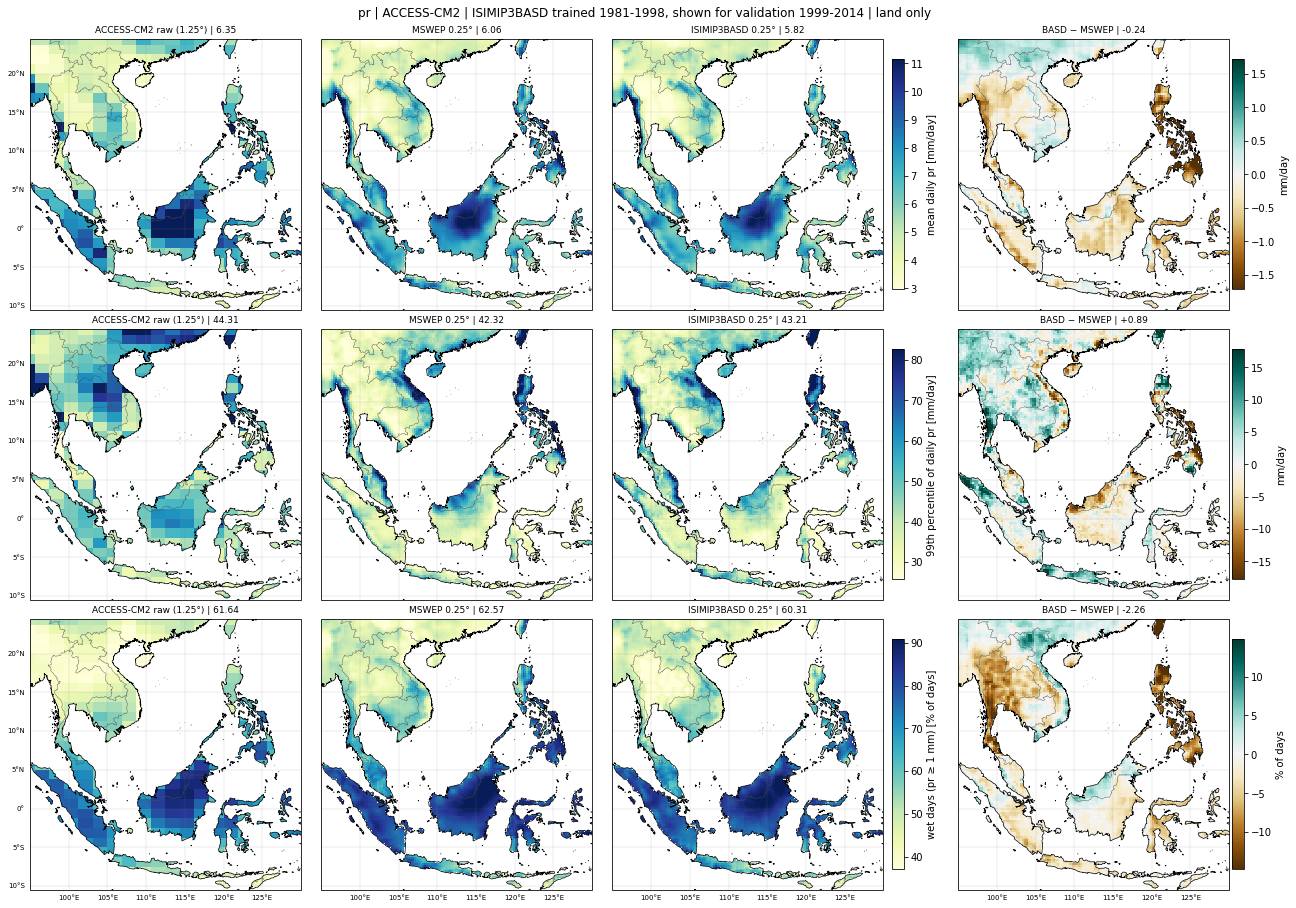

In [7]:
PC = ccrs.PlateCarree(); h = .5*float(np.median(np.diff(lat_f))); EXT = [lon_f[0]-h, lon_f[-1]+h, lat_f[0]-h, lat_f[-1]+h]
def deco(a, r, c, nr=3):
    a.set_extent(EXT, crs=PC)
    if NE:
        a.add_feature(cfeature.NaturalEarthFeature('physical', 'ocean', '10m'), facecolor='white', edgecolor='none', zorder=2)
        a.coastlines('10m', lw=.7, zorder=3); a.add_feature(cfeature.BORDERS.with_scale('10m'), lw=.4, edgecolor='.3', zorder=3)
    gl = a.gridlines(draw_labels=True, lw=.3, color='.5', alpha=.5, zorder=4); gl.top_labels = gl.right_labels = False
    gl.left_labels, gl.bottom_labels = c == 0, r == nr - 1; gl.xlabel_style = gl.ylabel_style = dict(size=7)
ROWS = [('mean', 'mean daily pr', 'mm/day'), ('p99', '99th percentile of daily pr', 'mm/day'), ('wet', f'wet days (pr ≥ {C["thr"]:g} mm)', '% of days')]
dg = float(np.median(np.diff(GV.lat.values)))
fig, ax = plt.subplots(3, 4, figsize=(18, 12.5), subplot_kw=dict(projection=PC), layout='constrained')
for r, (k, nm, u) in enumerate(ROWS):
    lim = np.nanpercentile(np.r_[E['OBS'][k][LM], E['BASD'][k][LM], E[GK][k][LM]], [2, 98])
    for c, (x, y, z, t) in enumerate([(GV.lon.values, GV.lat.values, EN[k], f'{MOD} raw ({dg:.2f}°) | {np.nanmean(E[GK][k][LM]):.2f}'),
                                      (lon_f, lat_f, np.where(LM, E['OBS'][k], np.nan), f'{OBS_NAME} 0.25° | {np.nanmean(E["OBS"][k][LM]):.2f}'),
                                      (lon_f, lat_f, np.where(LM, E['BASD'][k], np.nan), f'ISIMIP3BASD 0.25° | {np.nanmean(E["BASD"][k][LM]):.2f}')]):
        im = ax[r, c].pcolormesh(x, y, z, cmap='YlGnBu', vmin=lim[0], vmax=lim[1], shading='auto', transform=PC); ax[r, c].set_title(t, fontsize=9); deco(ax[r, c], r, c)
    fig.colorbar(im, ax=ax[r, :3], shrink=.85, pad=.01, label=f'{nm} [{u}]')
    b = np.where(LM, E['BASD'][k] - E['OBS'][k], np.nan); vb = max(float(np.nanpercentile(np.abs(b[LM]), 98)), 1e-6)
    im = ax[r, 3].pcolormesh(lon_f, lat_f, b, cmap='BrBG', vmin=-vb, vmax=vb, shading='auto', transform=PC)
    ax[r, 3].set_title(f'BASD − {OBS_NAME} | {np.nanmean(b[LM]):+.2f}', fontsize=9); deco(ax[r, 3], r, 3); fig.colorbar(im, ax=ax[r, 3], shrink=.85, pad=.01, label=u)
fig.suptitle(f'{V} | {MOD} | ISIMIP3BASD trained {CAL[0]}-{CAL[1]}, shown for validation {VAL[0]}-{VAL[1]} | land only', fontsize=12)
plt.show(); plt.close(fig)

## 7 · Distribution, annual cycle, and grid-point means
(a) Upper percentiles of daily pr pooled over land points (log scale). (b) Monthly climatology of the land mean. (c) 16-year mean per 0.25° land point against OBS; the 1:1 line is perfect, and the spread of the raw GCM and of the 1° BA output shows the spatial detail that only SD adds.

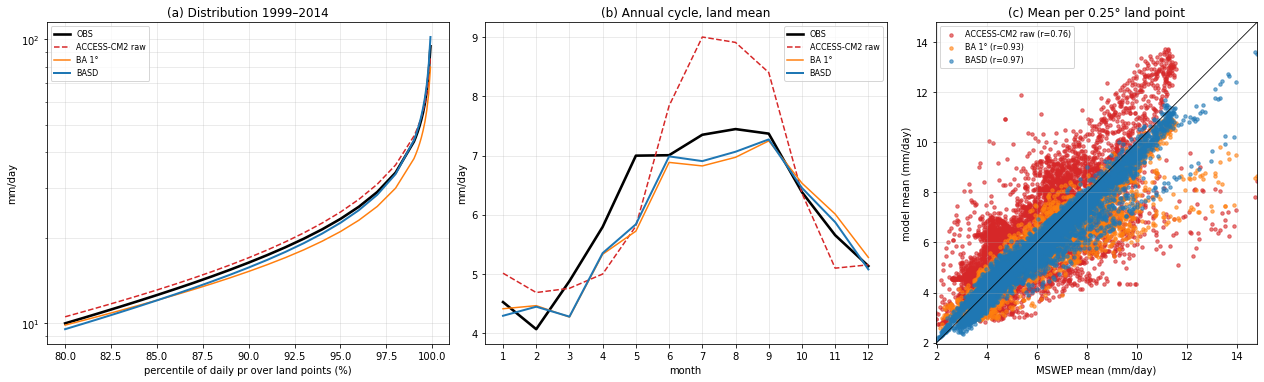

In [8]:
STY = {'OBS': dict(color='k', lw=2.6), GK: dict(color='tab:red', lw=1.5, ls='--'), BK: dict(color='tab:orange', lw=1.5), 'BASD': dict(color='tab:blue', lw=2)}
fig, ax = plt.subplots(1, 3, figsize=(18, 5.2), layout='constrained')
for k, S in E.items(): ax[0].plot(QP, S['pq'], label=k, **STY[k]); ax[1].plot(range(1, 13), S['mon'], label=k, **STY[k])
o = E['OBS']['mean'][LM]; lo_ = min(np.nanmin(E[k]['mean'][LM]) for k in E); hi_ = max(np.nanmax(E[k]['mean'][LM]) for k in E)
for k in (GK, BK, 'BASD'): ax[2].scatter(o, E[k]['mean'][LM], s=12, alpha=.6, color=STY[k]['color'], label=f'{k} (r={TAB.loc[k, "r_spatial"]:.2f})')
ax[2].plot([lo_, hi_], [lo_, hi_], 'k-', lw=.8)
ax[0].set(yscale='log', xlabel='percentile of daily pr over land points (%)', ylabel='mm/day', title=f'(a) Distribution {VAL[0]}–{VAL[1]}')
ax[1].set(xticks=range(1, 13), xlabel='month', ylabel='mm/day', title='(b) Annual cycle, land mean')
ax[2].set(xlim=(lo_, hi_), ylim=(lo_, hi_), aspect='equal', xlabel=f'{OBS_NAME} mean (mm/day)', ylabel='model mean (mm/day)', title='(c) Mean per 0.25° land point')
for a in ax: a.grid(alpha=.3, which='both'); a.legend(fontsize=8)
plt.show(); plt.close(fig)

## References
* Lange, S. (2019). Trend-preserving bias adjustment and statistical downscaling with ISIMIP3BASD (v1.0). *Geoscientific Model Development*, 12, 3055–3070.
* Cannon, A. J. (2018). Multivariate quantile mapping bias correction: an N-dimensional probability density function transform for climate model simulations of multiple variables. *Climate Dynamics*, 50, 31–49.
* Cannon, A. J., Sobie, S. R., & Murdock, T. Q. (2015). Bias correction of GCM precipitation by quantile mapping: how well do methods preserve changes in quantiles and extremes? *Journal of Climate*, 28, 6938–6959.
* Beck, H. E., et al. (2019). MSWEP V2 global 3-hourly 0.1° precipitation: methodology and quantitative assessment. *Bulletin of the American Meteorological Society*, 100, 473–500.
* Bi, D., et al. (2020). Configuration and spin-up of ACCESS-CM2, the new generation Australian Community Climate and Earth System Simulator Coupled Model. *Journal of Southern Hemisphere Earth Systems Science*, 70, 225–251.